![Python Banner](../../Image/05_08_Quasi_Experiemnts.png)


# 8.2 Synthetic Control Method

The Synthetic Control Method (SCM) is a powerful quasi-experimental technique for evaluating interventions when there is only one (or a few) treated units. It constructs a weighted combination of untreated donor units that reproduces the treated unit's pre-intervention trajectory, then uses this "synthetic" unit as the counterfactual.

## Overview

### The Core Idea

When you have only one treated unit (e.g., a single country, state, or flagship store), standard DiD struggles because you can't reasonably compare one unit to many controls. SCM solves this by creating a **synthetic control unit** — a weighted average of untreated donor units that matches the treated unit's characteristics and pre-treatment outcomes as closely as possible.

The method works in three steps:

1. **Construction**: Find nonnegative weights (summing to 1) over donor units such that the weighted combination matches the treated unit's pre-intervention outcomes (and optionally covariates)
2. **Counterfactual**: Project this weighted combination into the post-intervention period to estimate what would have happened without treatment
3. **Effect**: The gap between the treated unit's actual post-intervention outcome and its synthetic control's projected outcome is the treatment effect

### Business Setting

SCM is ideal when:

- You have **one or a few treated units** (a single market, country, or flagship location)
- There is a **pool of potential donor units** that were not treated
- You have **pre-intervention data** on both outcomes and covariates
- The treated unit is not an extreme outlier relative to the donor pool

Common business examples:

- A new policy tested in one state before nationwide rollout
- A store format piloted in a single flagship location
- A marketing campaign launched in one city
- A product feature tested in one country

### The Identifying Assumption

SCM's identifying assumption is: **the pre-period weighting that reproduces the treated unit's history would have continued to reproduce it absent treatment.**

This is more transparent than parallel trends in DiD because you can **visually inspect** how well the synthetic unit tracks the treated unit in the pre-period. The quality of this pre-period fit is the license to interpret the post-period gap.

### Why Business People Like SCM

SCM has several features that make it particularly persuasive to non-technical stakeholders:

1. **Transparency**: The counterfactual is interpretable — "Synthetic Chicago = 40% Minneapolis + 35% Detroit + 25% Cleveland"
2. **Visual**: The result is a picture (treated vs. synthetic over time), not just a coefficient
3. **Intuitive**: If the synthetic unit closely tracks the treated unit before treatment, it's reasonable to use it as a counterfactual after
4. **Case-study feel**: SCM naturally produces compelling narratives about specific interventions

### Key Advantages

- **Handles single treated units**: Works when DiD would be inappropriate
- **Transparent weights**: You can see exactly which donors contribute to the synthetic control
- **No extrapolation**: Weights are nonnegative and sum to 1, so the treated unit must lie within the donor pool's convex hull
- **Permutation inference**: Uses placebo tests (applying SCM to each donor) to construct p-values without distributional assumptions

## Implementation in Python

`SyntheticControl` chooses nonnegative donor weights that sum to one and match the treated unit before the intervention. The reported effect is the average post-period gap. The interval is a Bayesian bootstrap of the pre-period rows.

The setup matches the other PyCausalML tutorials: find the repository, import the package, and install the editable checkout only if the import fails.

## Set Up


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")
print("Repository:", root)


PyCausalML ready.
Repository: /home/zia207/Github/PyCausalML


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pycausalml import (
    SyntheticControl,

)

rng = np.random.default_rng(42)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("Imported PyCausalML")


Imported PyCausalML


## Simulated Example: Single Market Intervention

We'll simulate a scenario where a new program launches in one market only, with several untreated markets available as donors.

In [3]:
def make_market_panel(
    n_markets=12,
    n_weeks=104,
    treated_market=0,
    treat_week=60,
    true_effect=8.0,
    effect_ramp=6,
    seed=42,
):
    """Simulate market-level panel data with one treated market."""
    rng = np.random.default_rng(seed)
    
    # Market fixed effects and trends
    market_fe = rng.normal(100, 15, n_markets)
    market_trend = rng.normal(0.05, 0.03, n_markets)
    
    rows = []
    market_shock = rng.normal(0, 3, (n_markets, n_weeks))
    
    for w in range(n_weeks):
        season = 6 * np.sin(2 * np.pi * w / 52)
        for m in range(n_markets):
            treated_unit = (m == treated_market)
            post = w >= treat_week
            
            # Treatment effect ramps in
            if treated_unit and post:
                ramp = min(1.0, (w - treat_week + 1) / effect_ramp)
                tau = true_effect * ramp
            else:
                tau = 0.0
            
            y = (market_fe[m] + market_trend[m] * w
                 + season + market_shock[m, w]
                 + tau + rng.normal(0, 4))
            
            rows.append((m, w, int(treated_unit), int(post), y))
    
    return pd.DataFrame(rows, columns=[
        "market", "week", "treated", "post", "revenue"])

# Generate the panel
panel = make_market_panel()
print(panel.head())
print("\nTrue effect at full ramp: $8k/week")


   market  week  treated  post  revenue
0       0     0        1     0  101.786
1       1     0        0     0   83.973
2       2     0        0     0  109.709
3       3     0        0     0  112.188
4       4     0        0     0   67.768

True effect at full ramp: $8k/week


## Data Preparation for SCM

SCM requires data in a specific format: long format with unit, time, and outcome variables.

In [4]:

mkt_long = panel[["market", "week", "revenue"]].copy()
treated_market = 0
donor_markets = list(range(1, 12))
treat_week = 60
print(f"Treated market: {treated_market}")
print(f"Donor markets: {donor_markets}")
print(f"Treatment week: {treat_week}")


Treated market: 0
Donor markets: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Treatment week: 60


## Fitting the Synthetic Control

We use `SyntheticControl` from PyCausalML. Weights are nonnegative and sum to one, as in Abadie's synthetic control.


In [5]:

def _pivot(frame, week_min, week_max):
    subset = frame[(frame["week"] >= week_min) & (frame["week"] < week_max)]
    return subset.pivot(index="week", columns="market", values="revenue").sort_index()

donors = mkt_long[mkt_long["market"].isin(donor_markets)]
treated = mkt_long[mkt_long["market"] == treated_market]
donor_pre = _pivot(donors, 0, treat_week)
donor_post = _pivot(donors, treat_week, 104)
treated_pre = _pivot(treated, 0, treat_week).iloc[:, 0].to_numpy()
treated_post = _pivot(treated, treat_week, 104).iloc[:, 0].to_numpy()

scm = SyntheticControl(n_boot=80, random_state=0)
scm.fit(donor_pre.to_numpy(), treated_pre, donor_post.to_numpy(), treated_post)
weights = pd.Series(scm.weights_, index=donor_pre.columns, name="weight").sort_values(ascending=False)
print("Donor weights:")
print(weights.round(3))
print("\nPost-period average effect:")
print(pd.Series(scm.summary()).round(3))


Donor weights:
market
11   0.257
8    0.173
2    0.157
10   0.155
9    0.074
3    0.068
5    0.065
6    0.027
4    0.024
1    0.000
7    0.000
Name: weight, dtype: float64

Post-period average effect:
estimate         7.027
ci_lower         5.649
ci_upper         8.693
posterior_mean   7.107
dtype: float64


The weights show how much each donor market contributes to the synthetic control. For example, if Market 4 has weight 0.35, it means the synthetic control is 35% composed of Market 4's trajectory.

## Visualizing the Results

The most important diagnostic is the path plot, which shows how well the synthetic control tracks the treated unit.

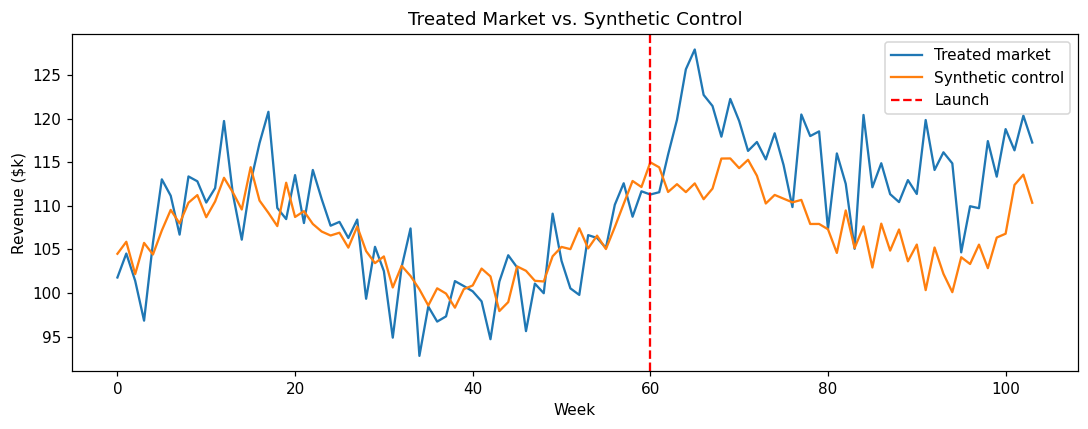

In [6]:

weeks = np.concatenate([donor_pre.index.to_numpy(), donor_post.index.to_numpy()])
synth_path = np.concatenate([donor_pre.to_numpy() @ scm.weights_, scm.synth_post_])
treated_path = np.concatenate([treated_pre, treated_post])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weeks, treated_path, label="Treated market")
ax.plot(weeks, synth_path, label="Synthetic control")
ax.axvline(treat_week, color="red", ls="--", label="Launch")
ax.set_xlabel("Week")
ax.set_ylabel("Revenue ($k)")
ax.set_title("Treated Market vs. Synthetic Control")
ax.legend()
fig.tight_layout()
plt.show()


The path plot should show:

- **Pre-period (weeks 0-59)**: The synthetic control should closely track the treated market
- **Post-period (weeks 60-103)**: A gap emerges between treated and synthetic — this is the estimated treatment effect

If the pre-period fit is poor, stop — the synthetic control is not a valid counterfactual.

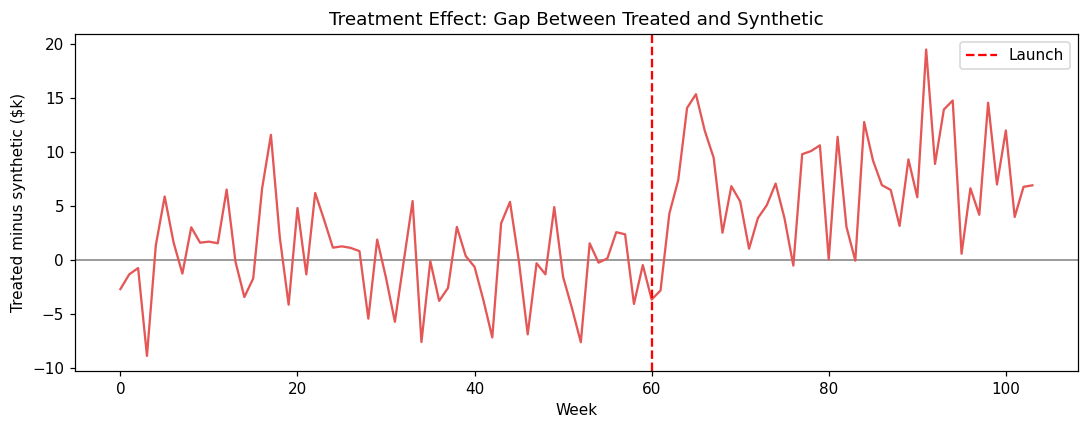

In [7]:

gap = treated_path - synth_path
fig, ax = plt.subplots(figsize=(10, 4))
ax.axhline(0, color="gray", lw=1)
ax.plot(weeks, gap, color="#E45756")
ax.axvline(treat_week, color="red", ls="--", label="Launch")
ax.set_xlabel("Week")
ax.set_ylabel("Treated minus synthetic ($k)")
ax.set_title("Treatment Effect: Gap Between Treated and Synthetic")
ax.legend()
fig.tight_layout()
plt.show()


The gaps plot shows the treatment effect over time. It should be near zero in the pre-period (indicating good fit) and show the effect in the post-period.

## Inference: Placebo-in-Space Permutation

With only one treated unit, standard errors don't apply. SCM uses **permutation inference**: apply the same procedure to every donor as if it were treated, then compare the real effect to the distribution of placebo effects.

1     1.550
2     1.670
3    -2.270
4    -7.320
5    -2.710
6     0.380
7     0.510
8    -0.560
9    -1.370
10    2.800
11   -0.160
Name: placebo_gap, dtype: float64


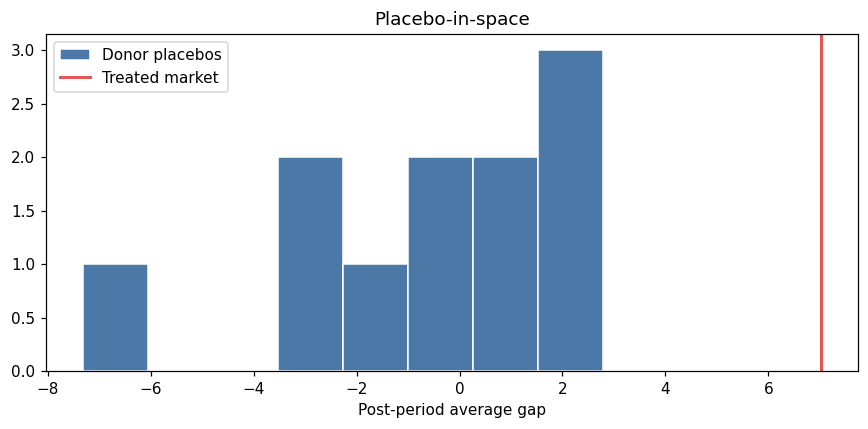

In [8]:

wide = (
    mkt_long.pivot(index="week", columns="market", values="revenue")
    .sort_index()
)
pre_w = wide.loc[wide.index < treat_week]
post_w = wide.loc[wide.index >= treat_week]

def post_mean_gap(unit):
    others = [column for column in wide.columns if column != unit]
    weights_u = SyntheticControl._weights(pre_w[others].to_numpy(), pre_w[unit].to_numpy())
    return float(np.mean(post_w[unit].to_numpy() - post_w[others].to_numpy() @ weights_u))

placebo_gaps = pd.Series(
    {unit: post_mean_gap(unit) for unit in donor_markets},
    name="placebo_gap",
)
print(placebo_gaps.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(placebo_gaps, bins=8, color="#4C78A8", edgecolor="white", label="Donor placebos")
ax.axvline(scm.effect_, color="#E45756", lw=2, label="Treated market")
ax.set_xlabel("Post-period average gap")
ax.set_title("Placebo-in-space")
ax.legend()
fig.tight_layout()
plt.show()


In [9]:

abs_placebo = np.abs(placebo_gaps.to_numpy())
pval = (np.sum(abs_placebo >= abs(scm.effect_)) + 1) / (len(abs_placebo) + 1)
print(f"Treated gap: {scm.effect_:.2f}")
print(f"Permutation p-value: {pval:.3f}")


Treated gap: 7.03
Permutation p-value: 0.167


The p-value indicates how unusual the real effect is compared to the placebo distribution. A low p-value (e.g., < 0.05) suggests the effect is unlikely to occur by chance.

## Diagnostics and Best Practices

### 1. Pre-Period Fit is Critical

The single most important diagnostic is the pre-period fit. If the synthetic control cannot track the treated unit before treatment, it cannot be trusted as a counterfactual after treatment.

**Rule of thumb**: Visual inspection should show close tracking in the pre-period. Consider quantitative metrics like pre-period mean squared prediction error (MSPE).

### 2. No Extrapolation

SCM weights are constrained to be nonnegative and sum to 1. This means the treated unit must lie within the donor pool's convex hull. A flagship market that is much larger than all donors cannot be synthesized well.

**Solutions**:
- Scale outcomes (e.g., revenue per store)
- Use augmented SCM (adds a bias-correcting outcome model)
- Exclude extreme outliers from the donor pool
- Consider alternative methods (DiD with multiple controls)

### 3. In-Time Placebo

Test the method by ending the data before the real intervention and imposing a fake treatment date. The "effect" should be near zero.

**Implementation**: Run SCM with a fake treatment week (e.g., week 40) using only data up to week 50. If you find a significant effect, the method is misspecified.

### 4. Leave-One-Out

Drop the highest-weight donor and refit. Conclusions should not hinge on a single donor. If results change dramatically, the analysis is fragile.

### 5. Don't Cherry-Pick the Donor Pool

Pre-specify the donor pool before seeing results. Changing the donor pool after seeing the effect is a form of p-hacking.

**Best practice**: Document the donor pool selection criteria in an analysis plan before running the analysis.

### 6. Include Covariates When Available

While outcome matching is the primary criterion, including pre-treatment covariates (e.g., market size, demographics) can improve the synthetic control's realism and transparency.

## Real-World Data

The series below is a real dataset shipped with [CausalPy](https://causalpy.readthedocs.io/en/stable/) (PyMC Labs), under the Apache License 2.0. The files live in [`causalpy/data`](https://github.com/pymc-labs/CausalPy/tree/main/causalpy/data).

```
@software{causalpy,
  author = {{PyMC Labs}},
  title = {CausalPy: Causal inference for quasi-experiments in Python},
  url = {https://github.com/pymc-labs/CausalPy},
  year = {2026}
}
```

PyCausalML fits the estimator. CausalPy is the data source. When CausalPy is installed, `causalpy.load_data` reads the packaged file. Otherwise the notebook reads the same CSV from that GitHub directory.

California Proposition 99 raised the cigarette tax in 1989. The series is annual per-capita cigarette sales for 39 states, 1970–2000, from Abadie, Diamond, and Hainmueller (2010), distributed with CausalPy as `california_prop99`. California is the treated state. The other states are the donor pool.


CausalPy is not installed. Loaded 'california_prop99' from
https://raw.githubusercontent.com/pymc-labs/CausalPy/main/causalpy/data/california_prop99.csv
Install the package with: pip install 'pycausalml[causalpy]'
Shape (31, 40).


Utah            0.394
Montana         0.232
Nevada          0.205
Connecticut     0.109
New Hampshire   0.045
Colorado        0.015
Illinois        0.000
Delaware        0.000
Name: weight, dtype: float64

Average post-1988 gap (packs per capita):
estimate         -19.510
ci_lower         -41.710
ci_upper         -18.810
posterior_mean   -34.490
dtype: float64


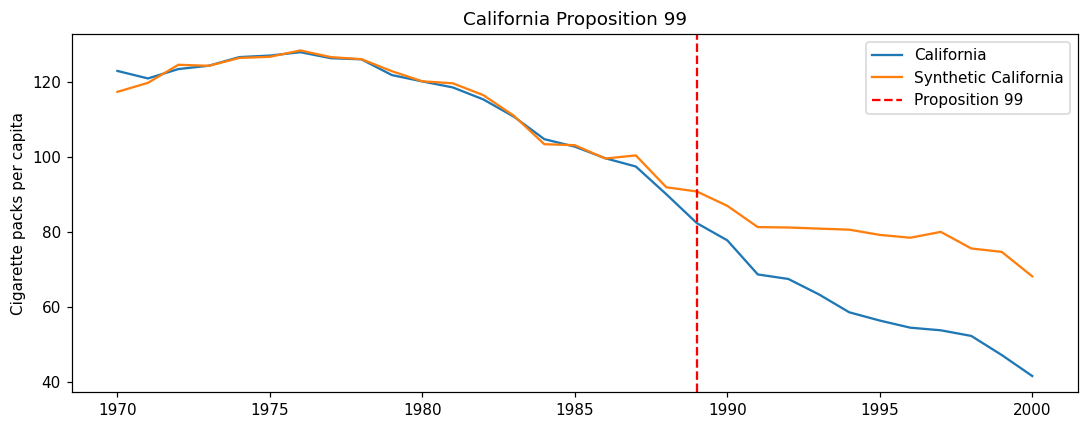

In [10]:
CAUSALPY_FILES = {
    "banks": "banks.csv",
    "covid": "deaths_and_temps_england_wales.csv",
    "drinking": "drinking.csv",
    "risk": "AJR2001.csv",
    "schoolReturns": "schoolingReturns.csv",
    "california_prop99": "california_prop99.csv",
}

def load_causalpy(name: str) -> pd.DataFrame:
    """Load a CausalPy example dataset.

    Uses causalpy.load_data when that package is installed. Otherwise reads
    the same CSV from the CausalPy GitHub data directory.
    """
    try:
        import causalpy as cp
        frame = cp.load_data(name)
        print(f"Loaded {name!r} with causalpy.load_data. Shape {frame.shape}.")
        return frame
    except ImportError:
        url = (
            "https://raw.githubusercontent.com/pymc-labs/CausalPy/main/causalpy/data/"
            + CAUSALPY_FILES[name]
        )
        frame = pd.read_csv(url)
        print(f"CausalPy is not installed. Loaded {name!r} from")
        print(url)
        print("Install the package with: pip install 'pycausalml[causalpy]'")
        print(f"Shape {frame.shape}.")
        return frame

prop = load_causalpy("california_prop99").set_index("Year").sort_index().astype(float)
treated_name = "California"
pre_years = prop.index < 1989
donors = prop.drop(columns=[treated_name])
scm_ca = SyntheticControl(n_boot=40, random_state=0)
scm_ca.fit(
    donors.loc[pre_years].to_numpy(),
    prop.loc[pre_years, treated_name].to_numpy(),
    donors.loc[~pre_years].to_numpy(),
    prop.loc[~pre_years, treated_name].to_numpy(),
)
ca_weights = pd.Series(scm_ca.weights_, index=donors.columns, name="weight")
print(ca_weights.sort_values(ascending=False).head(8).round(3))
print("\nAverage post-1988 gap (packs per capita):")
print(pd.Series(scm_ca.summary()).round(2))

synth_pre = donors.loc[pre_years].to_numpy() @ scm_ca.weights_
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(prop.index, prop[treated_name], label="California")
ax.plot(
    list(prop.index[pre_years]) + list(prop.index[~pre_years]),
    np.concatenate([synth_pre, scm_ca.synth_post_]),
    label="Synthetic California",
)
ax.axvline(1989, color="red", ls="--", label="Proposition 99")
ax.set_ylabel("Cigarette packs per capita")
ax.set_title("California Proposition 99")
ax.legend()
fig.tight_layout()
plt.show()


## Common Pitfalls

### 1. Poor Pre-Period Fit

If the synthetic control doesn't track the treated unit well before treatment, the post-period gap is meaningless.

**Solution**: Improve donor pool, add covariates, or use a different method.

### 2. Treated Unit is an Outlier

If the treated unit is extreme relative to donors (e.g., a megacity compared to small towns), no weighted combination can match it well.

**Solution**: Scale outcomes, use augmented SCM, or accept that SCM is not appropriate.

### 3. Too Few Donors

With very few donors, the synthetic control may be unstable or overfit to specific donors.

**Solution**: Use at least 5-10 donors when possible.

### 4. Contemporaneous Shocks

If something else affects the treated unit at the same time as the intervention, SCM will attribute the combined effect to the treatment.

**Solution**: Check for co-interventions and use multiple methods to triangulate.

### 5. Short Pre-Period

A short pre-period makes it hard to assess fit and may miss pre-existing trends.

**Solution**: Use at least 2-3 pre-intervention periods (years for annual data, months for monthly data).

## When to Use SCM

SCM is the right choice when:

- You have **one or few treated units**
- There is a **pool of untreated donors**
- The treated unit is **not an extreme outlier** relative to donors
- You have **sufficient pre-period data** to assess fit
- You value **transparency and visual communication**

Consider alternatives when:

- Many treated units → DiD
- Treatment assigned by threshold → RDD
- Treated unit is extreme outlier → Scale outcomes or use alternative methods
- No suitable donor pool → ITS, CausalImpact

## Summary

Synthetic Control is a powerful method for case-study causal inference with single treated units. Its strength lies in the transparency of the counterfactual construction and the intuitive visual presentation of results.

**Key takeaways:**

- SCM constructs a weighted combination of donors to match the treated unit's pre-intervention trajectory
- Pre-period fit is the critical diagnostic — if it's poor, stop
- Use permutation inference (placebo tests) for statistical significance
- Don't cherry-pick the donor pool — pre-specify it
- Be transparent about limitations when the treated unit is an outlier
- Combine with other methods (DiD, placebo tests) for stronger conclusions

## Scientific Terminology

Plain-language definitions for the terms in this tutorial are in the [scientific terminology glossary](../00-scientific-terminology-glossary.qmd).
